# Spotify 2023: Audio-Feature Structure Across Stream Popularity Levels

**Option 1: Distribution of audio features conditional on stream level**

### Research question
**Do the distributions and relationships of Spotify audio features differ across levels of streaming popularity?**

This notebook uses the Spotify 2023 dataset and the eight audio features:
- BPM
- Danceability
- Valence
- Energy
- Acousticness
- Instrumentalness
- Liveness
- Speechiness


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from pathlib import Path

output_dir = Path("/mnt/data/spotify_option1_outputs")
output_dir.mkdir(exist_ok=True)

print("Libraries loaded.")

Libraries loaded.


## 1. Upload and load the Spotify 2023 dataset

Run this cell and choose **spotify-2023.csv** from your computer.

In [2]:
csv_name = r"/mnt/data/spotify-2023.csv"

df = pd.read_csv(csv_name, encoding="latin1")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (953, 24)


,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,263,45,10,826,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,126,58,14,382,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,207,91,14,949,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,207,125,12,548,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,133,87,15,425,144,A,Minor,65,23,80,14,63,11,6


## 2. Define the eight audio features

In [3]:
features = [
    "bpm",
    "danceability_%",
    "valence_%",
    "energy_%",
    "acousticness_%",
    "instrumentalness_%",
    "liveness_%",
    "speechiness_%"
]

print("Audio features:")
for f in features:
    print("-", f)

Audio features:
- bpm
- danceability_%
- valence_%
- energy_%
- acousticness_%
- instrumentalness_%
- liveness_%
- speechiness_%


## 3. Clean the streams variable

The dataset contains one non-numeric entry in `streams`. We convert streams to numeric and remove only rows where the conversion fails.

In [4]:
df["streams_num"] = pd.to_numeric(
    df["streams"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

print("Invalid/missing stream values:", df["streams_num"].isna().sum())

df_analysis = df.dropna(subset=["streams_num"]).copy()

print("Songs used in analysis:", len(df_analysis))

Invalid/missing stream values: 1
Songs used in analysis: 952


## 4. Divide songs into four stream-popularity groups

We use **quartiles** so that each group contains the same number of songs:

- **Q1:** lowest-streamed 25%
- **Q2:** 25th–50th percentile
- **Q3:** 50th–75th percentile
- **Q4:** highest-streamed 25%

This operationalizes the idea of examining the audio-feature vector **conditional on stream level**.

In [5]:
quartile_labels = [
    "Q1: Lowest 25%",
    "Q2",
    "Q3",
    "Q4: Highest 25%"
]

df_analysis["stream_quartile"] = pd.qcut(
    df_analysis["streams_num"],
    q=4,
    labels=quartile_labels
)

quartile_summary = (
    df_analysis
    .groupby("stream_quartile", observed=True)["streams_num"]
    .agg(["count", "min", "max"])
)

display(quartile_summary)

,count,min,max
stream_quartile,,,
Q1: Lowest 25%,238,2762.0,1.413817e+08
Q2,238,141720999.0,2.902286e+08
Q3,238,290833204.0,6.738011e+08
Q4: Highest 25%,238,674072710.0,3.703895e+09


## 5. Compare average audio features across popularity groups

In [6]:
feature_means = (
    df_analysis
    .groupby("stream_quartile", observed=True)[features]
    .mean()
    .round(2)
)

display(feature_means)

feature_means.to_csv(
    output_dir / "feature_means_by_stream_quartile.csv"
)

,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
stream_quartile,,,,,,,,
Q1: Lowest 25%,120.35,67.49,51.12,64.71,28.50,1.42,19.13,11.28
Q2,124.03,68.63,53.80,65.25,27.41,1.82,18.47,11.55
Q3,123.96,67.24,51.91,63.32,25.52,1.87,17.70,9.65
Q4: Highest 25%,121.87,64.58,48.80,63.82,26.88,1.23,17.55,8.08


## 6. Boxplots of selected features

These plots show whether the distribution of an audio feature shifts across stream-popularity groups.

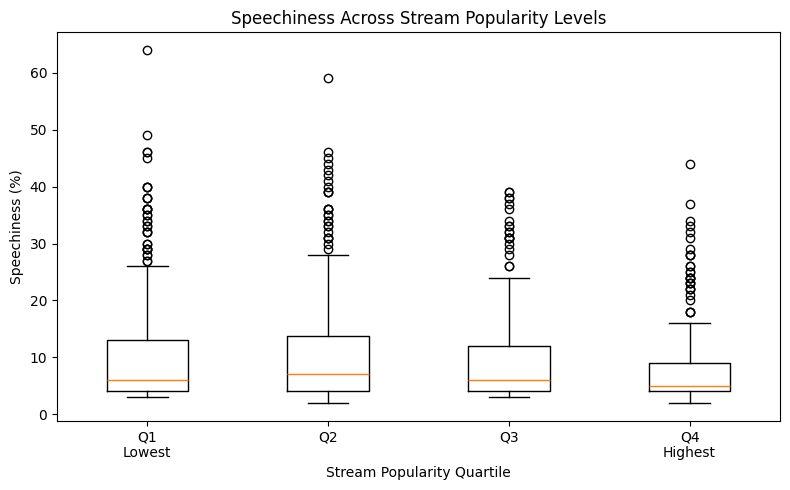

In [7]:
groups = [
    df_analysis.loc[
        df_analysis["stream_quartile"] == q,
        "speechiness_%"
    ].dropna()
    for q in df_analysis["stream_quartile"].cat.categories
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    groups,
    tick_labels=["Q1\nLowest", "Q2", "Q3", "Q4\nHighest"]
)

plt.xlabel("Stream Popularity Quartile")
plt.ylabel("Speechiness (%)")
plt.title("Speechiness Across Stream Popularity Levels")
plt.tight_layout()

plt.savefig(
    output_dir / "speechiness_pct_by_quartile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

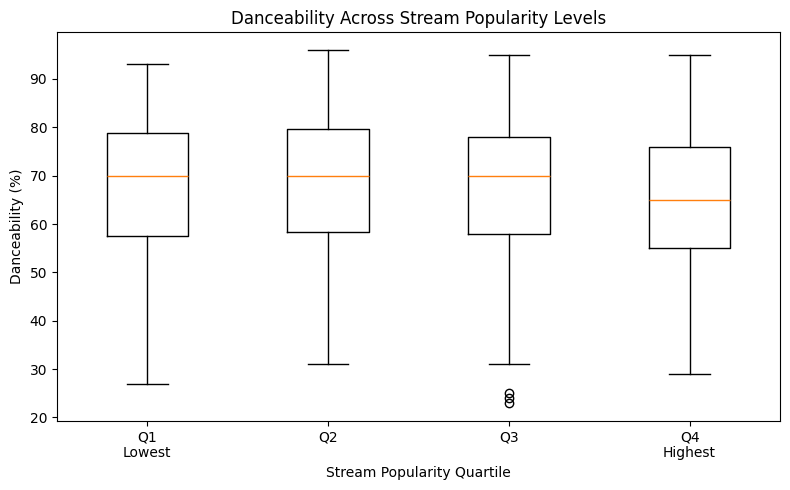

In [8]:
groups = [
    df_analysis.loc[
        df_analysis["stream_quartile"] == q,
        "danceability_%"
    ].dropna()
    for q in df_analysis["stream_quartile"].cat.categories
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    groups,
    tick_labels=["Q1\nLowest", "Q2", "Q3", "Q4\nHighest"]
)

plt.xlabel("Stream Popularity Quartile")
plt.ylabel("Danceability (%)")
plt.title("Danceability Across Stream Popularity Levels")
plt.tight_layout()

plt.savefig(
    output_dir / "danceability_pct_by_quartile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

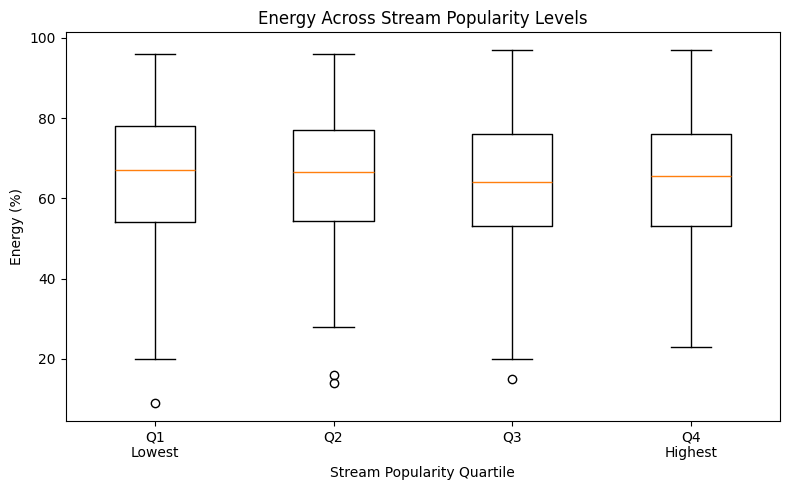

In [9]:
groups = [
    df_analysis.loc[
        df_analysis["stream_quartile"] == q,
        "energy_%"
    ].dropna()
    for q in df_analysis["stream_quartile"].cat.categories
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    groups,
    tick_labels=["Q1\nLowest", "Q2", "Q3", "Q4\nHighest"]
)

plt.xlabel("Stream Popularity Quartile")
plt.ylabel("Energy (%)")
plt.title("Energy Across Stream Popularity Levels")
plt.tight_layout()

plt.savefig(
    output_dir / "energy_pct_by_quartile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

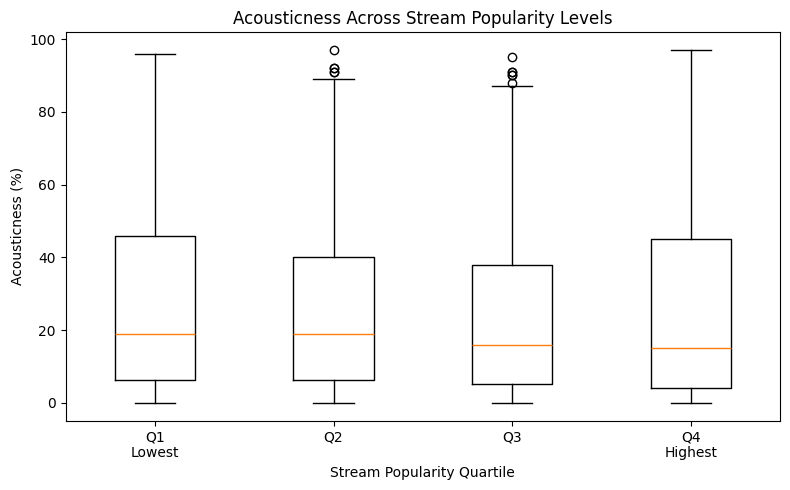

In [10]:
groups = [
    df_analysis.loc[
        df_analysis["stream_quartile"] == q,
        "acousticness_%"
    ].dropna()
    for q in df_analysis["stream_quartile"].cat.categories
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    groups,
    tick_labels=["Q1\nLowest", "Q2", "Q3", "Q4\nHighest"]
)

plt.xlabel("Stream Popularity Quartile")
plt.ylabel("Acousticness (%)")
plt.title("Acousticness Across Stream Popularity Levels")
plt.tight_layout()

plt.savefig(
    output_dir / "acousticness_pct_by_quartile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 7. Kruskal–Wallis tests across the four popularity groups

For each audio feature:

\[
H_0: \text{the feature distribution is the same across Q1, Q2, Q3, and Q4.}
\]

A small p-value provides evidence that at least one popularity group differs.

We use the Kruskal–Wallis test because several Spotify audio features are strongly skewed.

In [11]:
results = []

for feature in features:
    groups = [
        df_analysis.loc[
            df_analysis["stream_quartile"] == q,
            feature
        ].dropna()
        for q in df_analysis["stream_quartile"].cat.categories
    ]

    H, p = kruskal(*groups)

    results.append({
        "Feature": feature,
        "Kruskal-Wallis H": H,
        "p-value": p
    })

kw_results = pd.DataFrame(results)

kw_results["Conclusion (alpha=0.05)"] = np.where(
    kw_results["p-value"] < 0.05,
    "Evidence of a difference",
    "No significant evidence"
)

kw_results["Kruskal-Wallis H"] = kw_results["Kruskal-Wallis H"].round(3)
kw_results["p-value"] = kw_results["p-value"].round(4)

kw_results = kw_results.sort_values("p-value")

display(kw_results)

kw_results.to_csv(
    output_dir / "kruskal_wallis_results.csv",
    index=False
)

,Feature,Kruskal-Wallis H,p-value,Conclusion (alpha=0.05)
7,speechiness_%,16.248,0.0010,Evidence of a difference
1,danceability_%,9.068,0.0284,Evidence of a difference
2,valence_%,5.538,0.1364,No significant evidence
4,acousticness_%,2.788,0.4254,No significant evidence
6,liveness_%,2.715,0.4377,No significant evidence
0,bpm,2.441,0.4861,No significant evidence
3,energy_%,2.242,0.5237,No significant evidence
5,instrumentalness_%,1.325,0.7233,No significant evidence


## 8. Compare the correlation structure within each popularity group

The professor's suggestion is not limited to comparing individual feature averages. We also examine whether **relationships among the audio features** change across stream levels.

In [12]:
correlation_matrices = {}

for q in df_analysis["stream_quartile"].cat.categories:
    subset = df_analysis[
        df_analysis["stream_quartile"] == q
    ]
    correlation_matrices[q] = subset[features].corr()

print("Q1 correlation matrix:")
display(correlation_matrices["Q1: Lowest 25%"].round(2))

print("Q4 correlation matrix:")
display(correlation_matrices["Q4: Highest 25%"].round(2))

Q1 correlation matrix:


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
bpm,1.00,0.03,0.03,0.15,-0.12,0.05,-0.10,-0.02
danceability_%,0.03,1.00,0.37,0.23,-0.25,0.02,-0.18,0.09
valence_%,0.03,0.37,1.00,0.37,-0.02,-0.13,-0.04,0.09
energy_%,0.15,0.23,0.37,1.00,-0.55,-0.04,0.07,-0.03
acousticness_%,-0.12,-0.25,-0.02,-0.55,1.00,0.02,-0.08,0.02
instrumentalness_%,0.05,0.02,-0.13,-0.04,0.02,1.00,-0.03,-0.09
liveness_%,-0.10,-0.18,-0.04,0.07,-0.08,-0.03,1.00,-0.08
speechiness_%,-0.02,0.09,0.09,-0.03,0.02,-0.09,-0.08,1.00


Q4 correlation matrix:


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
bpm,1.00,-0.30,-0.10,0.04,0.04,0.04,0.03,0.05
danceability_%,-0.30,1.00,0.50,0.21,-0.22,-0.21,-0.12,0.24
valence_%,-0.10,0.50,1.00,0.42,-0.25,-0.10,-0.02,0.02
energy_%,0.04,0.21,0.42,1.00,-0.67,0.05,0.03,0.08
acousticness_%,0.04,-0.22,-0.25,-0.67,1.00,-0.07,-0.01,-0.07
instrumentalness_%,0.04,-0.21,-0.10,0.05,-0.07,1.00,0.00,-0.10
liveness_%,0.03,-0.12,-0.02,0.03,-0.01,0.00,1.00,0.05
speechiness_%,0.05,0.24,0.02,0.08,-0.07,-0.10,0.05,1.00


### Correlation heatmap: Q1 (lowest-streamed 25%)

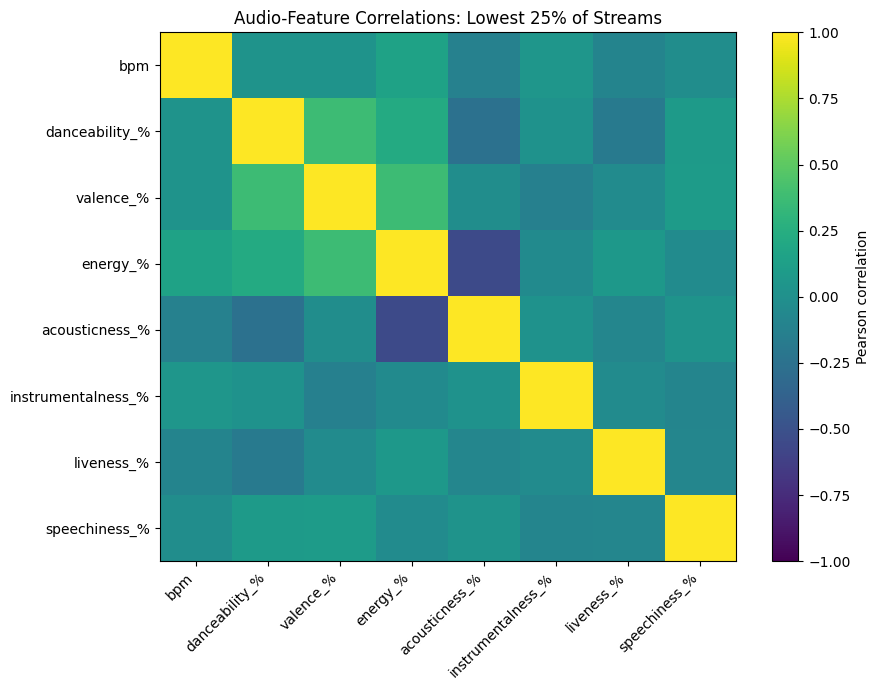

In [13]:
corr_q1 = correlation_matrices["Q1: Lowest 25%"]

plt.figure(figsize=(9, 7))
plt.imshow(corr_q1, aspect="auto", vmin=-1, vmax=1)

plt.xticks(
    range(len(features)),
    features,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(features)), features)

plt.colorbar(label="Pearson correlation")
plt.title("Audio-Feature Correlations: Lowest 25% of Streams")
plt.tight_layout()

plt.savefig(
    output_dir / "correlation_heatmap_Q1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Correlation heatmap: Q4 (highest-streamed 25%)

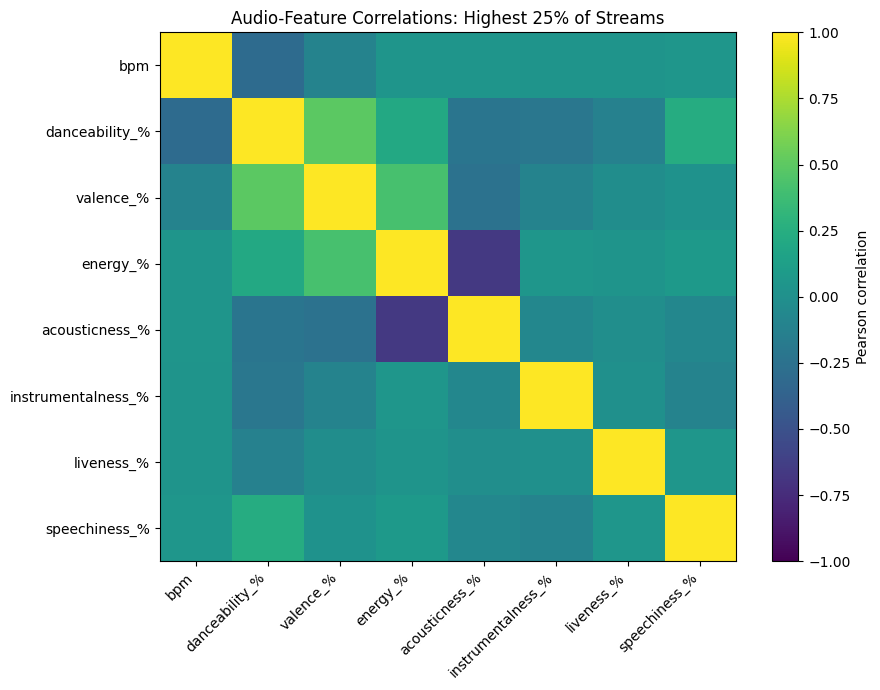

In [14]:
corr_q4 = correlation_matrices["Q4: Highest 25%"]

plt.figure(figsize=(9, 7))
plt.imshow(corr_q4, aspect="auto", vmin=-1, vmax=1)

plt.xticks(
    range(len(features)),
    features,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(features)), features)

plt.colorbar(label="Pearson correlation")
plt.title("Audio-Feature Correlations: Highest 25% of Streams")
plt.tight_layout()

plt.savefig(
    output_dir / "correlation_heatmap_Q4.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 9. Track key relationships across Q1–Q4

We focus on three relationships already identified in the earlier EDA:
- Energy vs Acousticness
- Danceability vs Valence
- Energy vs Valence


In [15]:
relationship_results = []

for q in df_analysis["stream_quartile"].cat.categories:
    subset = df_analysis[
        df_analysis["stream_quartile"] == q
    ]

    corr = subset[features].corr()

    relationship_results.append({
        "Stream Group": q,
        "Energy vs Acousticness":
            corr.loc["energy_%", "acousticness_%"],
        "Danceability vs Valence":
            corr.loc["danceability_%", "valence_%"],
        "Energy vs Valence":
            corr.loc["energy_%", "valence_%"]
    })

relationship_df = pd.DataFrame(relationship_results)

for col in relationship_df.columns[1:]:
    relationship_df[col] = relationship_df[col].round(3)

display(relationship_df)

relationship_df.to_csv(
    output_dir / "key_correlations_by_quartile.csv",
    index=False
)

,Stream Group,Energy vs Acousticness,Danceability vs Valence,Energy vs Valence
0,Q1: Lowest 25%,-0.553,0.369,0.375
1,Q2,-0.551,0.378,0.299
2,Q3,-0.543,0.372,0.337
3,Q4: Highest 25%,-0.671,0.498,0.419


## 10. Q1 vs Q4 scatterplots

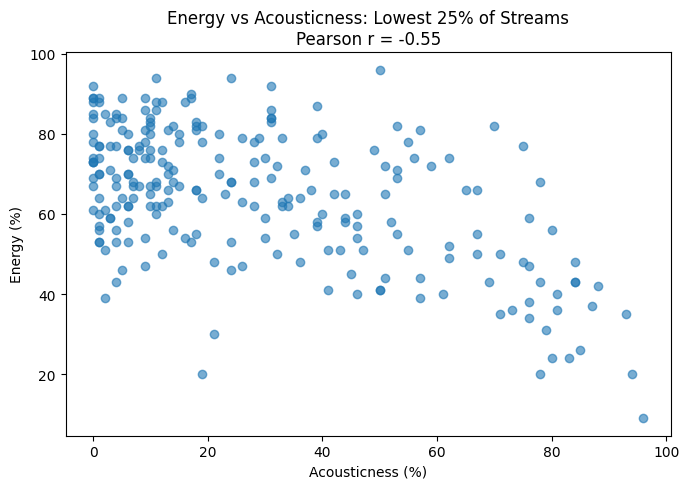

In [16]:
subset = df_analysis[
    df_analysis["stream_quartile"] == "Q1: Lowest 25%"
]

r = subset["energy_%"].corr(subset["acousticness_%"])

plt.figure(figsize=(7, 5))
plt.scatter(
    subset["acousticness_%"],
    subset["energy_%"],
    alpha=0.6
)

plt.xlabel("Acousticness (%)")
plt.ylabel("Energy (%)")
plt.title(
    "Energy vs Acousticness: Lowest 25% of Streams\n"
    f"Pearson r = {r:.2f}"
)
plt.tight_layout()

plt.savefig(
    output_dir / "energy_vs_acousticness_Q1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

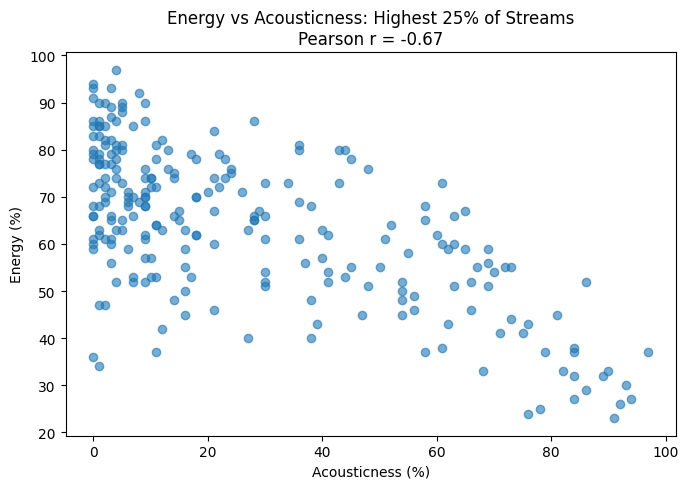

In [17]:
subset = df_analysis[
    df_analysis["stream_quartile"] == "Q4: Highest 25%"
]

r = subset["energy_%"].corr(subset["acousticness_%"])

plt.figure(figsize=(7, 5))
plt.scatter(
    subset["acousticness_%"],
    subset["energy_%"],
    alpha=0.6
)

plt.xlabel("Acousticness (%)")
plt.ylabel("Energy (%)")
plt.title(
    "Energy vs Acousticness: Highest 25% of Streams\n"
    f"Pearson r = {r:.2f}"
)
plt.tight_layout()

plt.savefig(
    output_dir / "energy_vs_acousticness_Q4.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

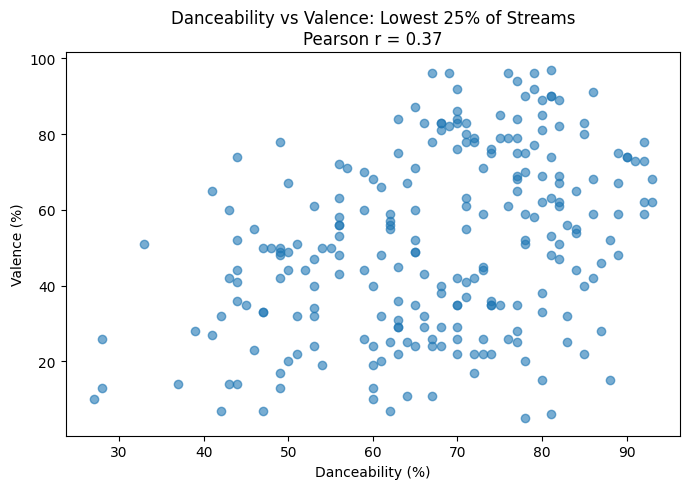

In [18]:
subset = df_analysis[
    df_analysis["stream_quartile"] == "Q1: Lowest 25%"
]

r = subset["danceability_%"].corr(subset["valence_%"])

plt.figure(figsize=(7, 5))
plt.scatter(
    subset["danceability_%"],
    subset["valence_%"],
    alpha=0.6
)

plt.xlabel("Danceability (%)")
plt.ylabel("Valence (%)")
plt.title(
    "Danceability vs Valence: Lowest 25% of Streams\n"
    f"Pearson r = {r:.2f}"
)
plt.tight_layout()

plt.savefig(
    output_dir / "danceability_vs_valence_Q1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

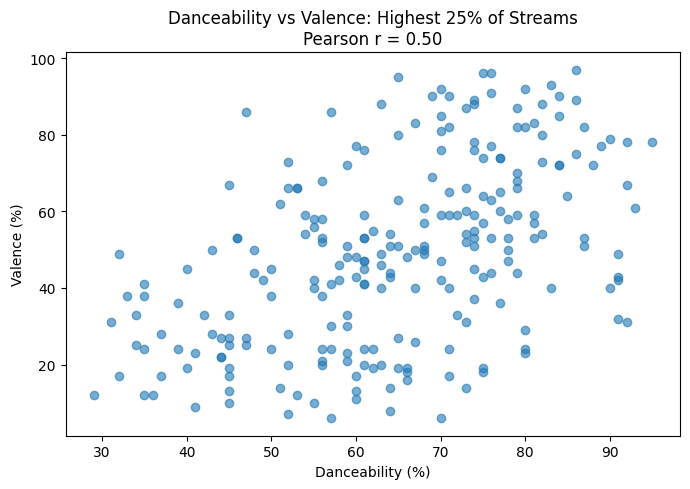

In [19]:
subset = df_analysis[
    df_analysis["stream_quartile"] == "Q4: Highest 25%"
]

r = subset["danceability_%"].corr(subset["valence_%"])

plt.figure(figsize=(7, 5))
plt.scatter(
    subset["danceability_%"],
    subset["valence_%"],
    alpha=0.6
)

plt.xlabel("Danceability (%)")
plt.ylabel("Valence (%)")
plt.title(
    "Danceability vs Valence: Highest 25% of Streams\n"
    f"Pearson r = {r:.2f}"
)
plt.tight_layout()

plt.savefig(
    output_dir / "danceability_vs_valence_Q4.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 11. Main findings to report

After running the notebook, the main results for this Spotify 2023 file should be approximately:

- **952 songs** have valid numeric stream counts and are used in this analysis.
- The quartile split gives **238 songs per popularity group**.
- **Speechiness** shows the strongest evidence of a distributional difference across stream quartiles.
- **Danceability** also shows evidence of a difference, but weaker than speechiness.
- Most other individual audio features show substantial overlap across popularity groups.
- The **Energy–Acousticness** relationship is negative in every quartile and is stronger among the highest-streamed songs.
- The **Danceability–Valence** relationship is positive in every quartile and is also stronger among the highest-streamed songs.
- This suggests that popularity groups may differ not only in individual feature levels, but also in the **joint structure of the audio features**.

### Important interpretation
These results describe association, not causation. We should not claim that a feature *causes* a song to receive more streams.


In [20]:
print("Saved presentation-ready outputs to:")
print(output_dir)

print("\nFiles:")
for p in sorted(output_dir.iterdir()):
    print("-", p.name)

Saved presentation-ready outputs to:
/mnt/data/spotify_option1_outputs

Files:
- acousticness_pct_by_quartile.png
- correlation_heatmap_Q1.png
- correlation_heatmap_Q4.png
- danceability_pct_by_quartile.png
- danceability_vs_valence_Q1.png
- danceability_vs_valence_Q4.png
- energy_pct_by_quartile.png
- energy_vs_acousticness_Q1.png
- energy_vs_acousticness_Q4.png
- feature_means_by_stream_quartile.csv
- key_correlations_by_quartile.csv
- kruskal_wallis_results.csv
- speechiness_pct_by_quartile.png
